In [1]:
set datafile columnheaders
set datafile separator comma
set style fill solid 0 border lc rgb "black"
height = 1
width = 1
fn = "out"
data = "output/data/"
unset colorbox

In [2]:
%%reset
set terminal postscript eps size width*6,height*3 color font "Times" 16
set output "output/plots/" . fn . ".ps"
replot
set terminal pngcairo size width*12inch,height*4inch
fn="out"

set terminal postscript eps size width*6,height*3 color font "Times" 16

Terminal type is now 'postscript'
Options are 'eps enhanced defaultplex \
   leveldefault color colortext \
   dashlength 1.0 linewidth 1.0 pointscale 1.0 butt noclip \
   nobackground \
   palfuncparam 2000,0.003 \
    noadobeglyphnames \
   size 6.00in, 3.00in "Times" 16  fontscale 1.0 '
replot
         ^
         no previous plot

set terminal pngcairo size width*12inch,height*4inch

Terminal type is now 'pngcairo'
Options are ' background "#ffffff" enhanced fontscale 1.0 size 12.00in, 4.00in '

# Favourite-longshot bias

## General

In [3]:
set key right top
set key auto columnheader box opaque
set style data lines
set xlabel "Betfair Starting Price"
set logscale x
set xrange[1:1000]

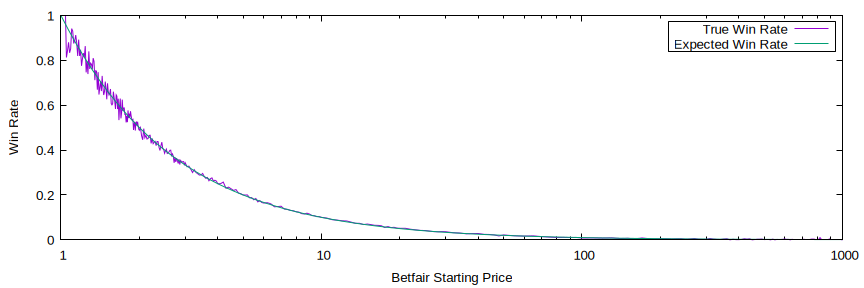

In [4]:
set ylabel "Win Rate"
    plot data . 'all-fl.csv' using 1:(column("mean")) title "True Win Rate", 1/x title "Expected Win Rate"
fn="all-fl"

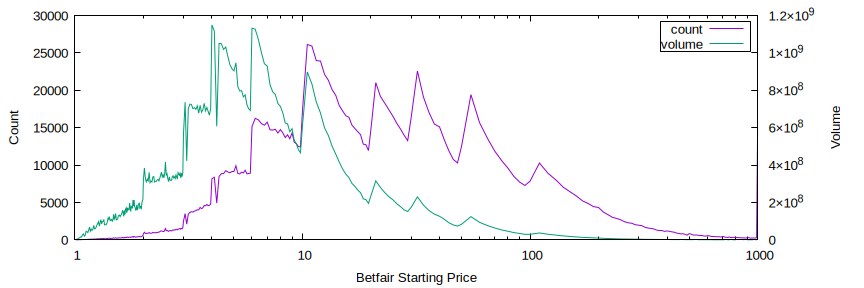

In [5]:
set ylabel "Count"
set y2label "Volume"
set y2tics
plot data . 'all-fl.csv' using 1:(column("count")), '' using 1:(column("volume")) axes x1y2
unset y2label
unset y2tics
fn="all-count-vol"

## Groupings

In [6]:
cats = "race_no distance_f hour race_type location nrunners ppvol overround"

In [7]:
fn="race_no"
#set key inside left bottom offset 1,0
#set key maxcols 3 maxrows 5
set key width 0
set title "race number"
set style data lines
set tics nomirror
set border 31
unset margins
set xtics right

In [8]:
width=2
height=4

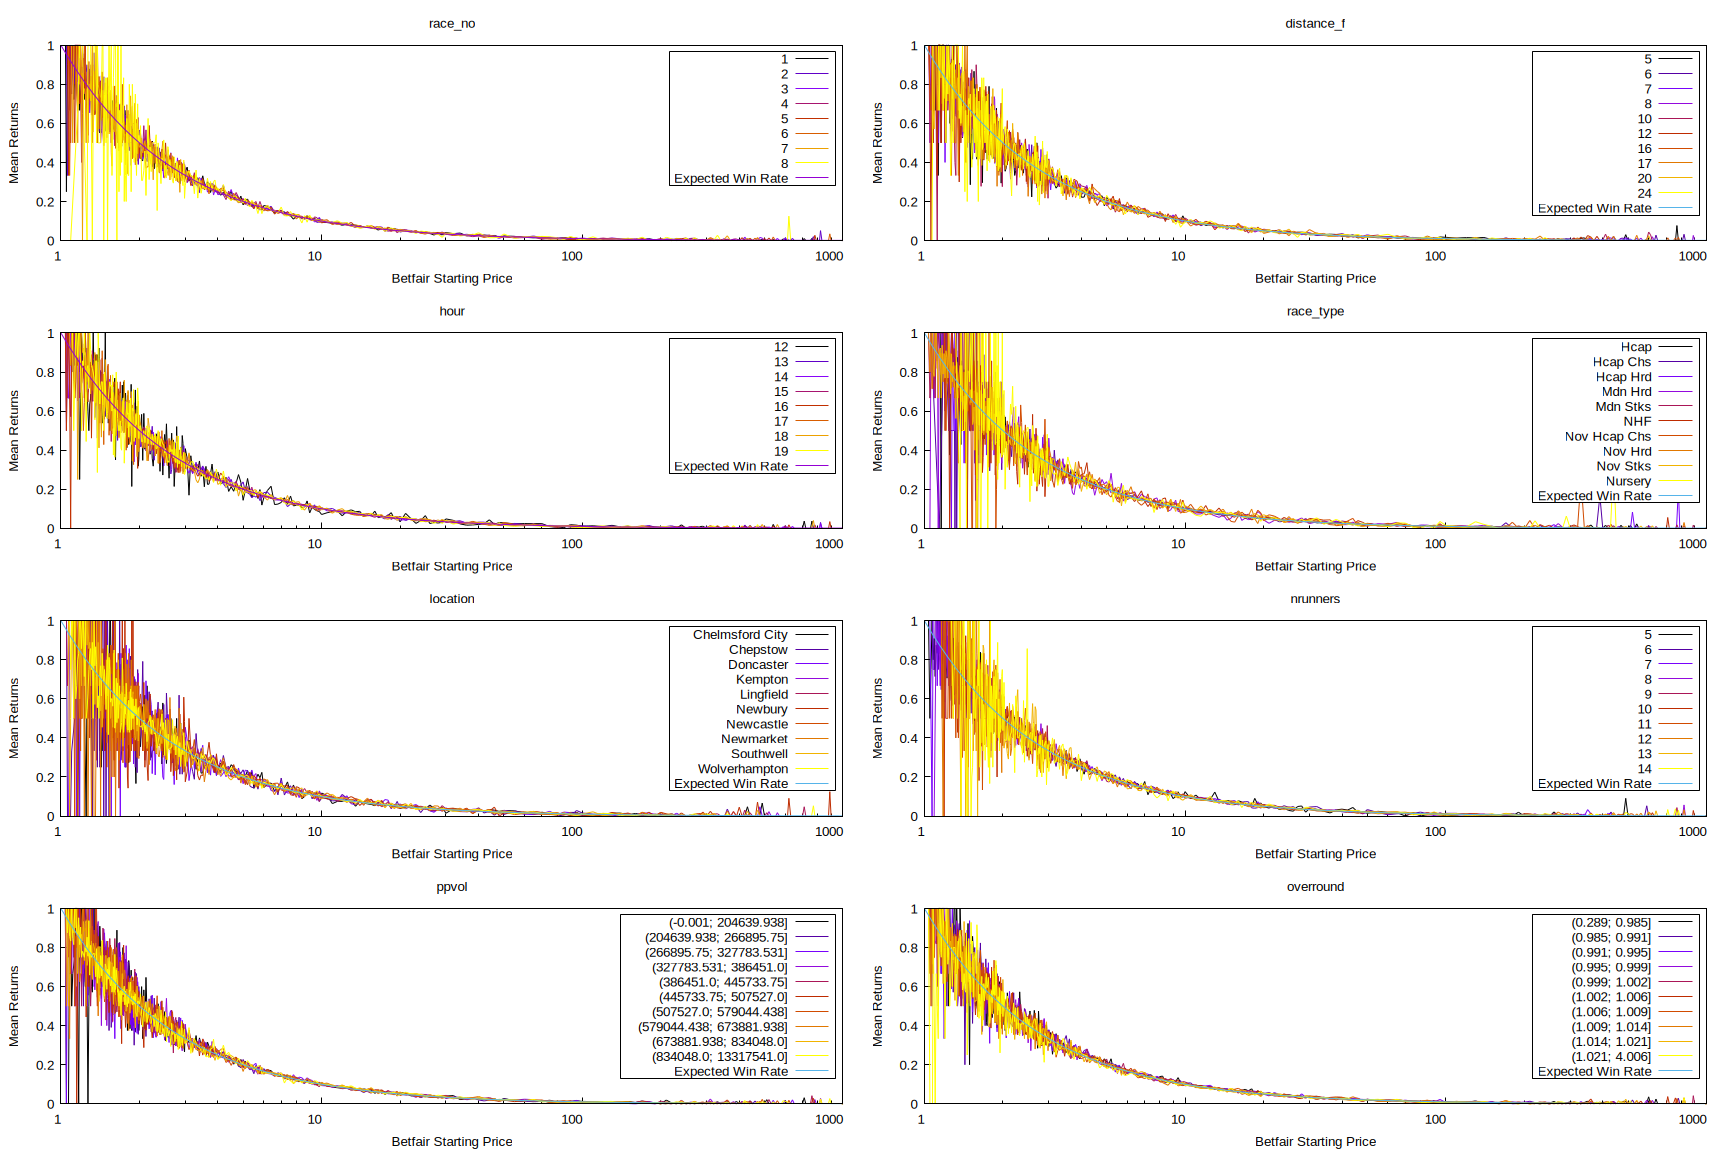

In [9]:
fn="groups-fl-mean"
set multiplot layout 4,2
unset colorbox
set ylabel "Mean Returns"
do for [c in cats] {
    f = data . c . '-fl-mean.csv'
    set title (c) noenhanced
    plot for [COL=2:*] f using 1:COL:(COL) lc palette, 1/x title "Expected Win Rate"
}
unset multiplot

In [10]:
width=2
height=4

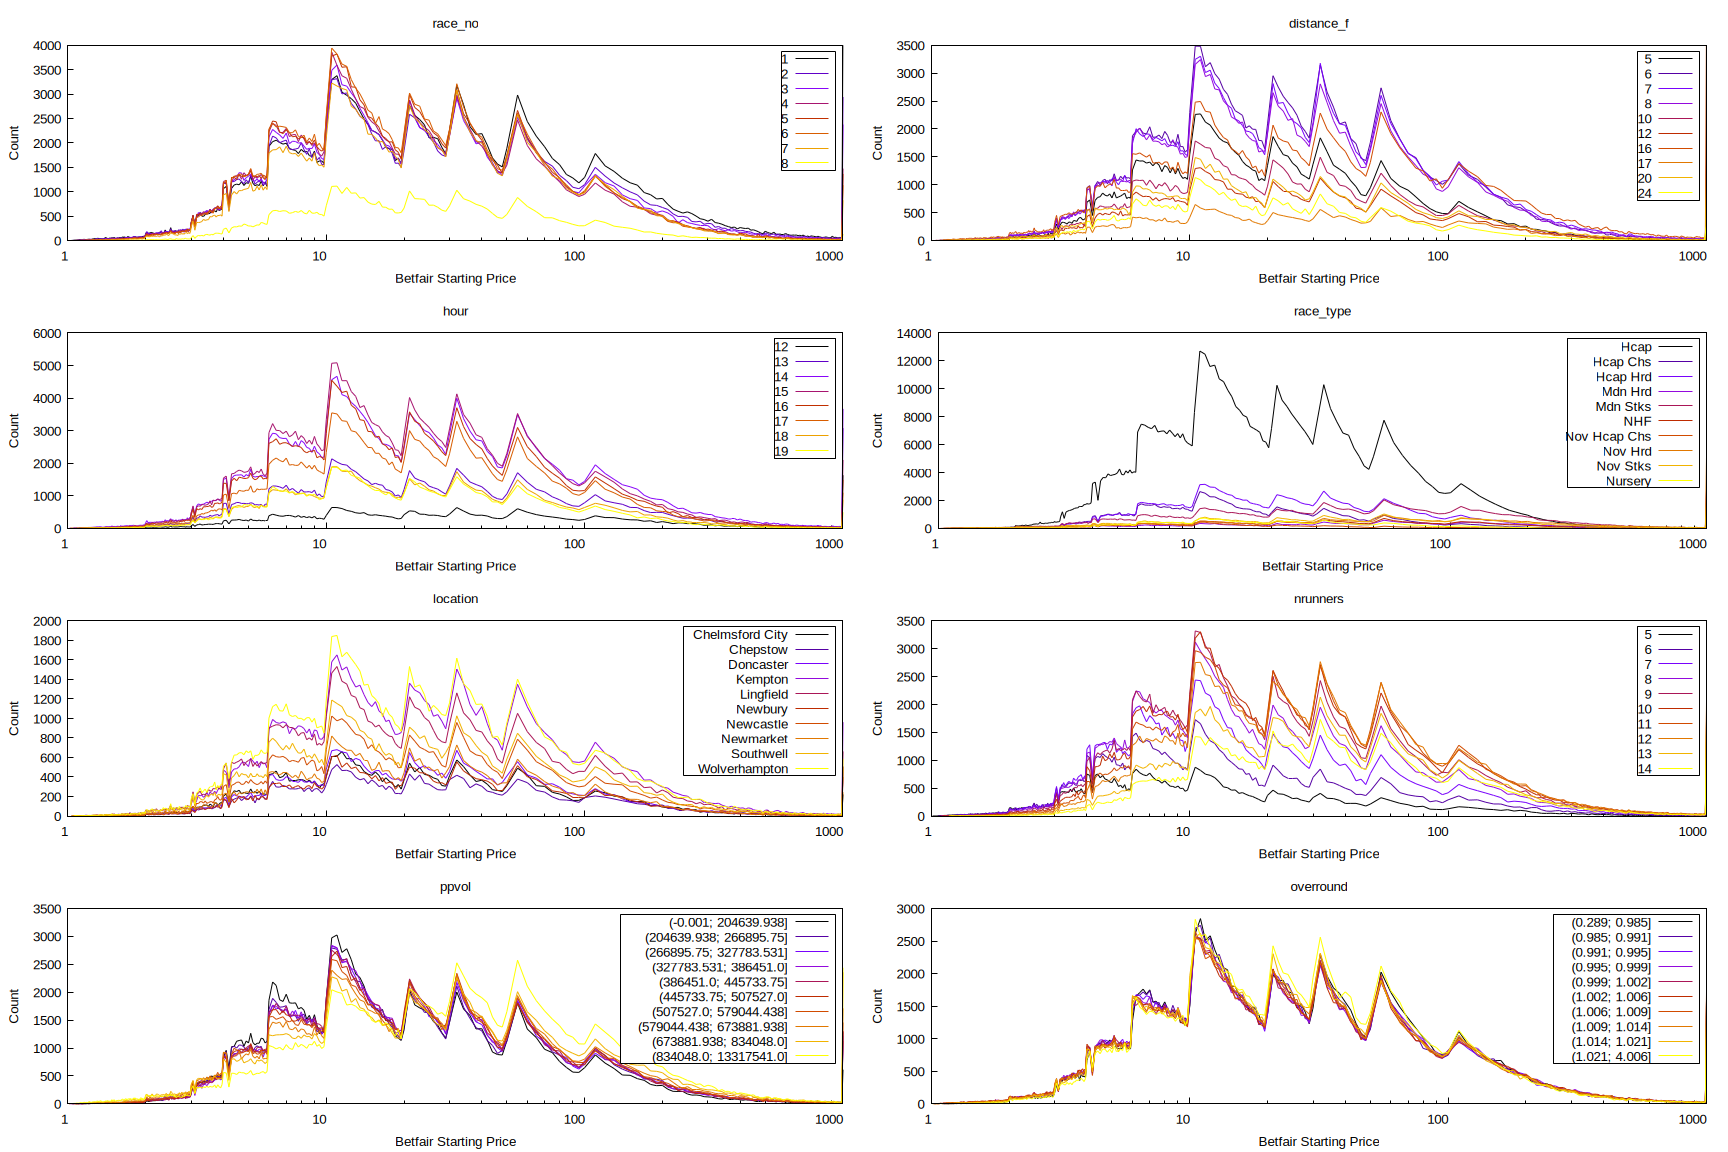

In [11]:
fn="groups-fl-count"
#set key inside left top
set multiplot layout 4,2
unset colorbox
set ylabel "Count"
do for [c in cats] {
    f = data . c . '-fl-count.csv'
    set title (c) noenhanced
    plot for [COL=2:*] f using 1:COL:(COL) lc palette
}
unset multiplot

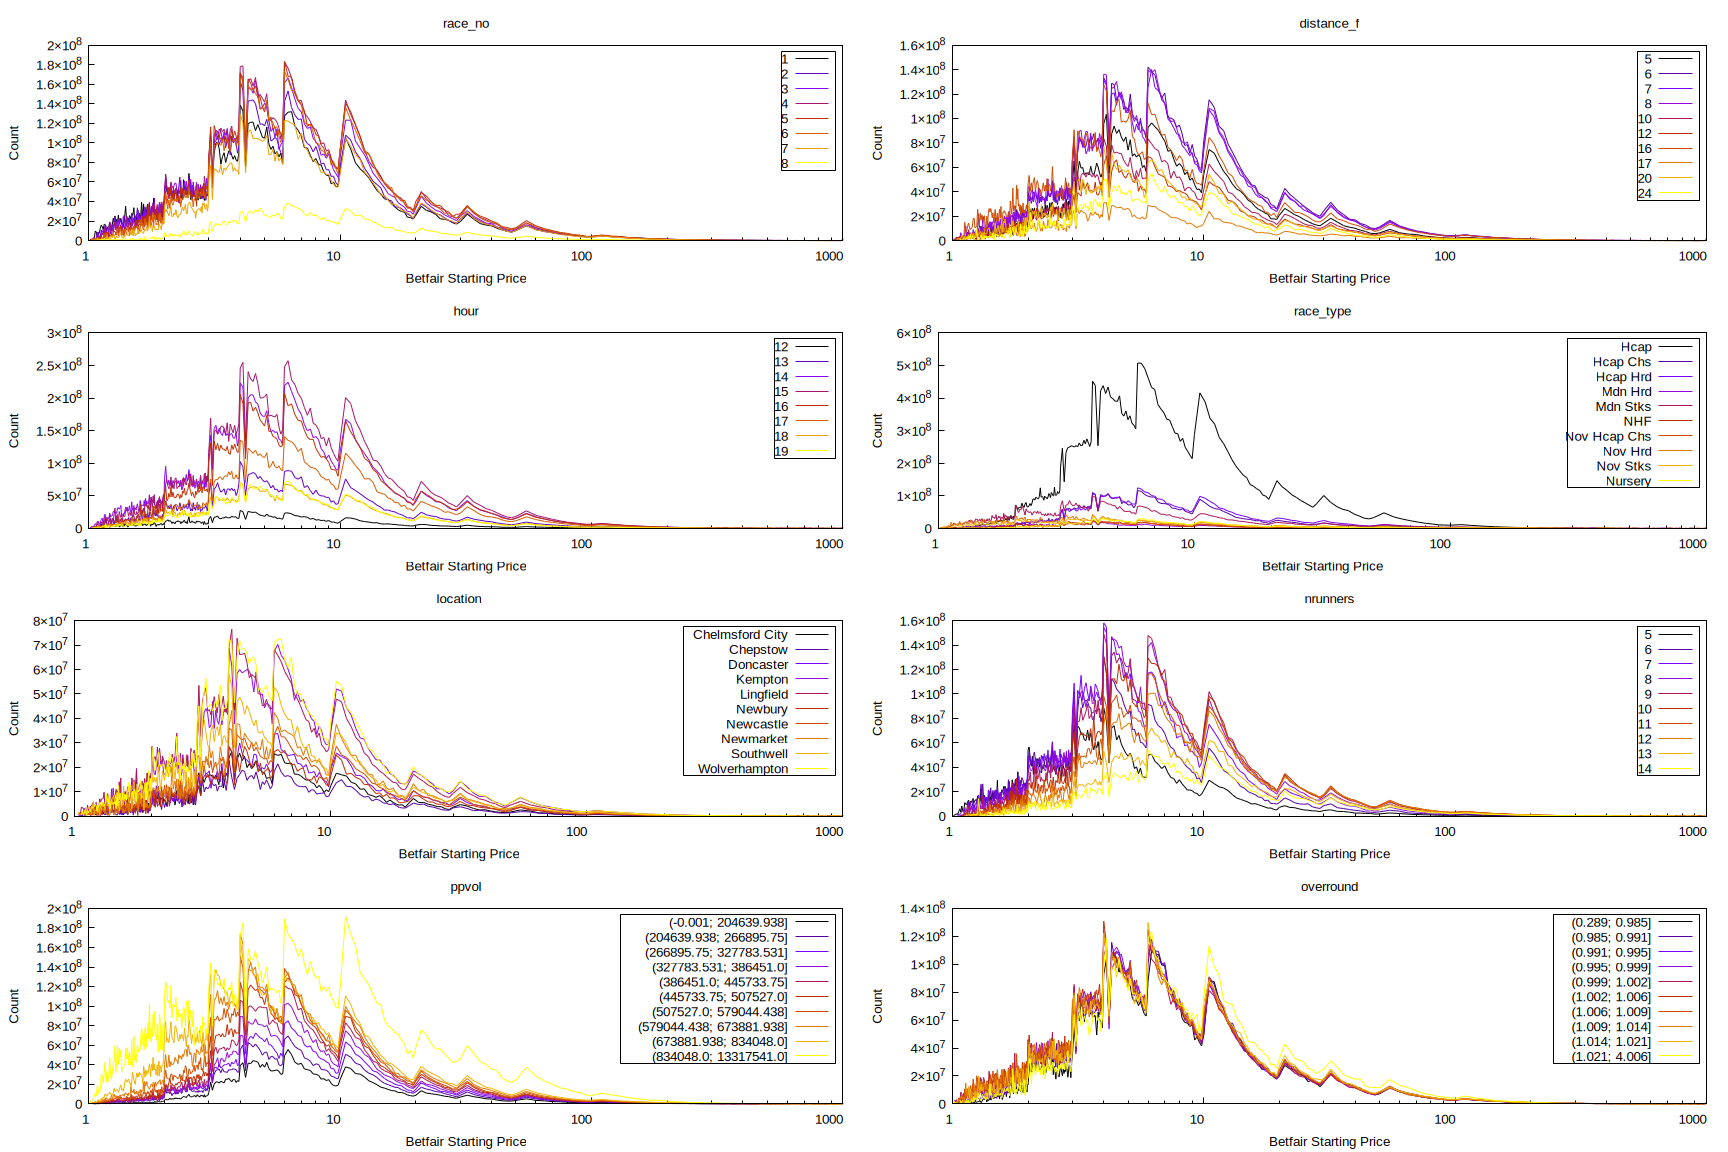

In [12]:
fn="groups-fl-vol"
#set key inside left top
set multiplot layout 4,2
unset colorbox
set ylabel "Count"
do for [c in cats] {
    f = data . c . '-fl-sum.csv'
    set title (c) noenhanced
    plot for [COL=2:*] f using 1:COL:(COL) lc palette
}
unset multiplot